# Détection d'anomalies routières : visualisation des données
Dataset **RoadAnomaly** : 60 images de routes avec un masque (0 = fond, 2 = anomalie).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DOSSIER = r"C:\Users\troud\Desktop\RoadAnomaly"
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
FRAMES = os.path.join(DOSSIER, "frames")

def charger(nom):
    img = np.array(Image.open(f"{FRAMES}/{nom}.webp").convert("RGB"))
    masque = np.array(Image.open(f"{FRAMES}/{nom}.labels/labels_semantic.png")) == 2
    return img, masque

noms = sorted(f[:-5] for f in os.listdir(FRAMES) if f.endswith(".webp"))
df = pd.DataFrame({"nom": noms})
df["type"] = df["nom"].str.split("_").str[0].str.rstrip("0123456789").replace("lost", "tires")
df["anomalie_%"] = [charger(n)[1].mean() * 100 for n in noms]
print(len(df), "images")

60 images


## 1. Exemples d'images et masques

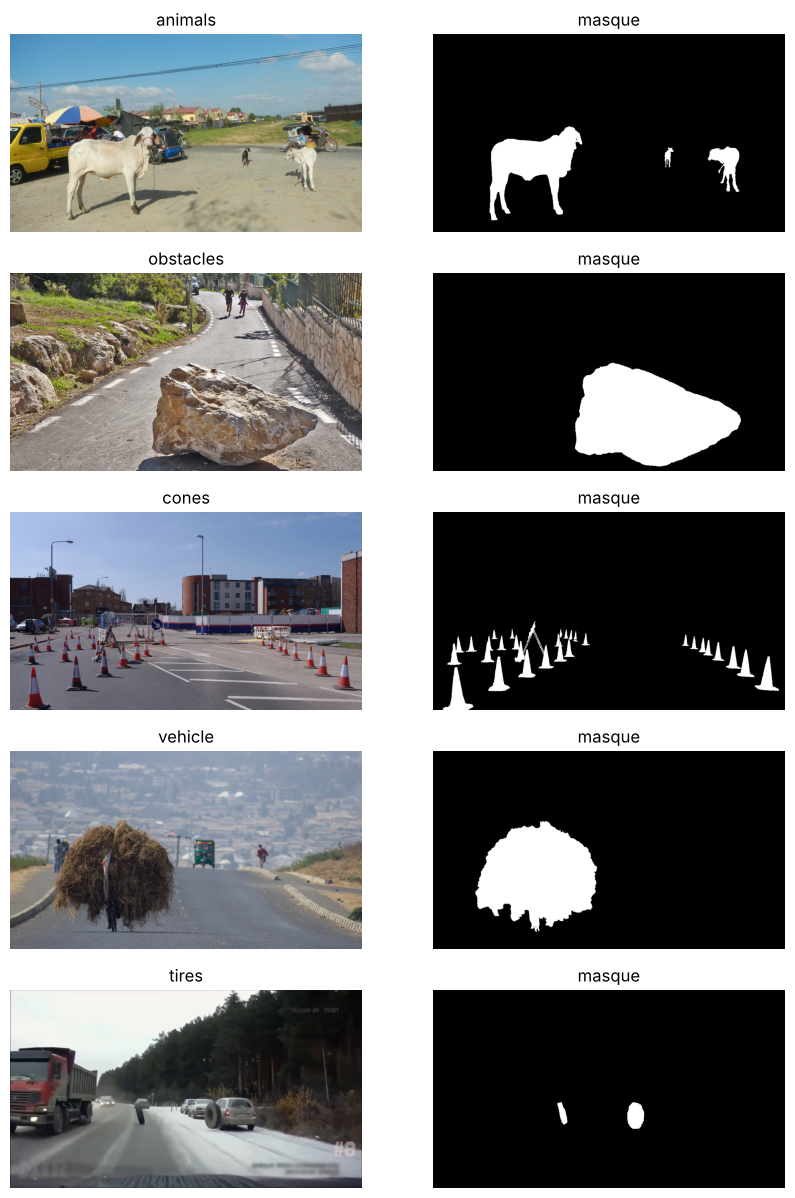

In [2]:
types = ["animals", "obstacles", "cones", "vehicle", "tires"]
fig, ax = plt.subplots(5, 2, figsize=(10, 15))
for i, t in enumerate(types):
    img, m = charger(df[df.type == t].nom.iloc[0])
    ax[i, 0].imshow(img); ax[i, 0].set_title(t)
    ax[i, 1].imshow(m, cmap="gray"); ax[i, 1].set_title("masque")
    ax[i, 0].axis("off"); ax[i, 1].axis("off")
plt.show()

**Résultat :** photos réelles très variées (pays, météo, caméras). Les masques sont précis et suivent bien les objets.

## 2. Nombre d'images par type

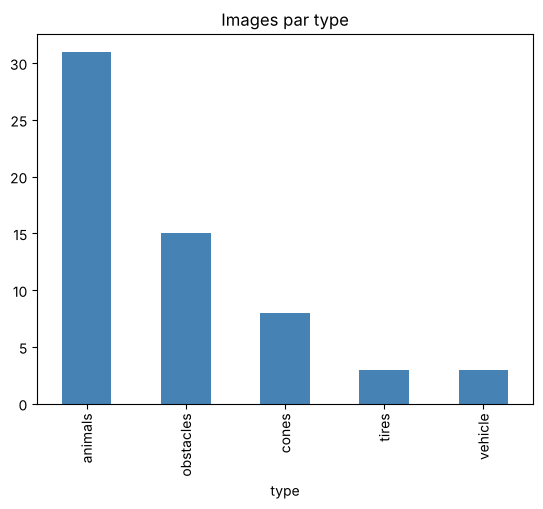

In [3]:
df["type"].value_counts().plot.bar(color="steelblue", title="Images par type")
plt.show()

**Résultat :** classes déséquilibrées : 31 animaux, mais seulement 3 véhicules et 3 pneus. On regroupe vehicle + tires dans une classe « autre ».

## 3. Pixels fond / anomalie

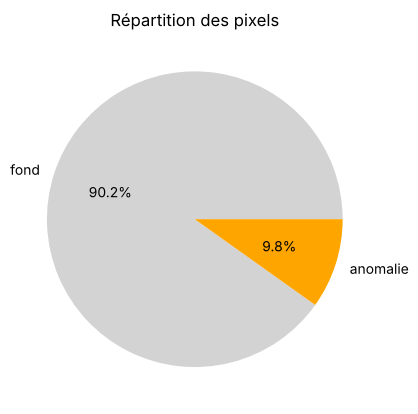

In [4]:
p = df["anomalie_%"].mean()
plt.pie([100 - p, p], labels=["fond", "anomalie"], autopct="%.1f%%", colors=["lightgray", "orange"])
plt.title("Répartition des pixels")
plt.show()

**Résultat :** seulement ≈ 10 % des pixels sont des anomalies. Il faut une perte adaptée (Dice / Focal) et mesurer avec l'IoU.

## 4. Taille des anomalies par type

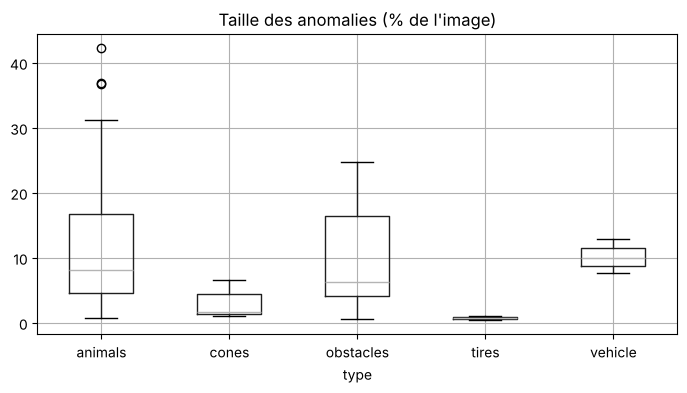

In [5]:
df.boxplot(column="anomalie_%", by="type", figsize=(8, 4))
plt.title("Taille des anomalies (% de l'image)"); plt.suptitle("")
plt.show()

**Résultat :** tailles très différentes, de 0,4 % à 42 % de l'image. Les cônes et pneus sont tout petits, les animaux peuvent être très grands → modèle multi-échelle (DeepLabV3+).

## 5. Position des anomalies dans l'image

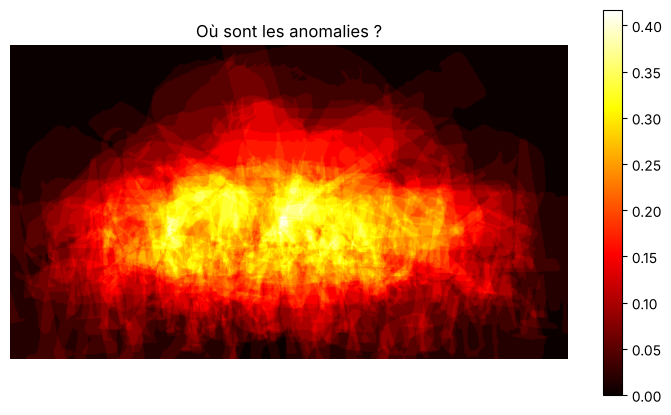

In [6]:
carte = sum(charger(n)[1].astype(float) for n in noms) / len(noms)
plt.figure(figsize=(9, 5))
plt.imshow(carte, cmap="hot"); plt.colorbar()
plt.title("Où sont les anomalies ?"); plt.axis("off")
plt.show()

**Résultat :** les anomalies sont surtout au centre de l'image (sur la route). On utilisera des augmentations (recadrage, flip) pour que le modèle ne retienne pas seulement la position.

## Conclusion
- Peu d'images (60) → transfer learning + augmentation de données
- Classes déséquilibrées → regrouper les petites classes, F1 macro
- 10 % de pixels anomalie → Dice / Focal loss, IoU
- Tailles très variées → modèle multi-échelle